In [33]:
import pandas as pd 
import matplotlib.pyplot as plt
df=pd.read_csv('E-commerce Data Analysis Project.csv')
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
df.head()

Rows: 185950
Columns: ['Column1', 'Order ID', 'Product Category', 'Product', 'Quantity Ordered', 'Price Each', 'Order Date', 'Purchase Address', 'Month', 'Sales', 'City', 'Hour', 'Time of Day']


,Column1,Order ID,Product Category,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Month,Sales,City,Hour,Time of Day
0,0,295665,Laptops and Computers,Macbook Pro Laptop,1,1700.00,30-12-2019 00:01,"136 Church St, New York City, NY 10001",12,1700.00,New York City,0,Night
1,1,295666,Home Appliances,LG Washing Machine,1,600.00,29-12-2019 07:03,"562 2nd St, New York City, NY 10001",12,600.00,New York City,7,Morning
2,2,295667,Charging Cables,USB-C Charging Cable,1,11.95,12-12-2019 18:21,"277 Main St, New York City, NY 10001",12,11.95,New York City,18,Evening
3,3,295668,Monitors,27in FHD Monitor,1,149.99,22-12-2019 15:13,"410 6th St, San Francisco, CA 94016",12,149.99,San Francisco,15,Afternoon
4,4,295669,Charging Cables,USB-C Charging Cable,1,11.95,18-12-2019 12:38,"43 Hill St, Atlanta, GA 30301",12,11.95,Atlanta,12,Afternoon


In [5]:
# Removed the useless index column
df = df.drop(columns=["Column1"])


In [13]:
# Converted date to real datetime
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%d-%m-%Y %H:%M")

In [17]:
# Converted money and quantity columns to numbers
df["Sales"] = pd.to_numeric(df["Sales"]) 
df["Quantity Ordered"] = pd.to_numeric(df["Quantity Ordered"])

In [19]:
# Dropped rows with missing date an sales amount
df = df.dropna(subset=["Order Date", "Sales"])


In [23]:
print("Total revenue:$", round(df["Sales"].sum(), 2))

Total revenue:$ 34492035.97


In [24]:
print("Unique orders:", df["Order ID"].nunique())


Unique orders: 178437


In [25]:
print("Units sold:", df["Quantity Ordered"].sum())

Units sold: 209079


In [28]:
# average and median are calculated (per product) not per order
print("Average order value : $", round(df["Sales"].mean(), 2))

Average order value : $ 185.49


In [29]:
print("Median order value  : $", round(df["Sales"].median(), 2))


Median order value  : $ 14.95


In [31]:
# tables and charts 
# revenue by product category
category_sales = df.groupby("Product Category")["Sales"].sum().sort_values(ascending=False)
print(category_sales)

Product Category
Laptops and Computers     12167558.70
Phones and Accessories     8940700.00
Monitors                   6377228.78
Audio Devices              3941193.86
Entertainment Devices      1445700.00
Home Appliances             787200.00
Charging Cables             633595.40
Batterie                    198859.23
Name: Sales, dtype: float64


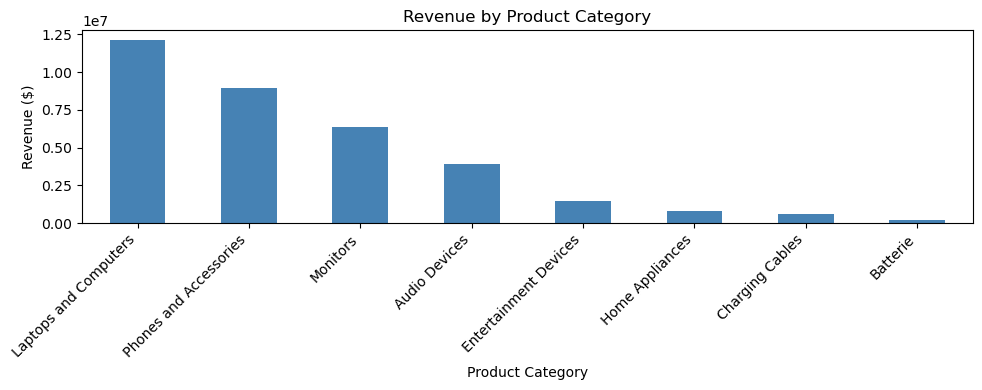

In [34]:
category_sales.plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.title("Revenue by Product Category")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [35]:
# top 10 cities by revenue
city_sales = df.groupby("City")["Sales"].sum().sort_values(ascending=False).head(10)
print(city_sales)

City
San Francisco    8262203.91
Los Angeles      5452570.80
New York City    4664317.43
Boston           3661642.01
Atlanta          2795498.58
Dallas           2767975.40
Seattle          2747755.48
Portland         2320490.61
Austin           1819581.75
Name: Sales, dtype: float64


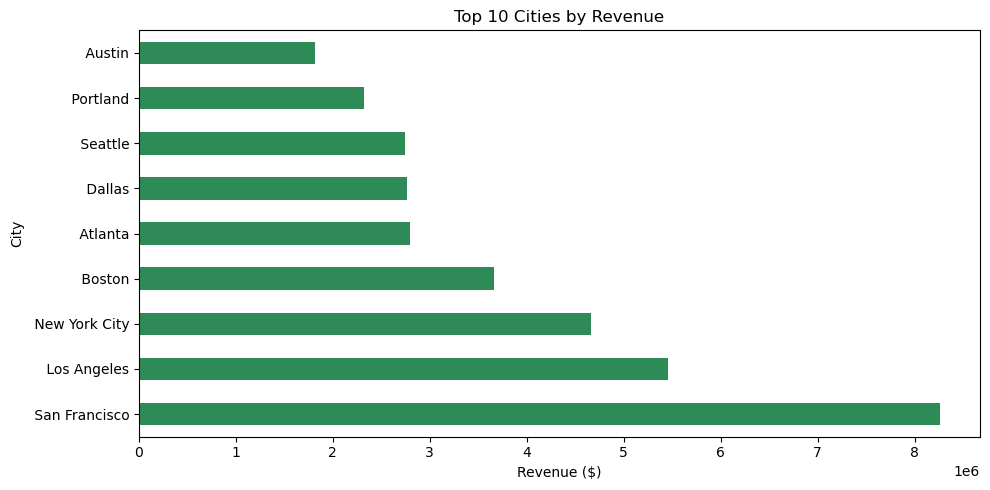

In [38]:
city_sales.plot(kind="barh", figsize=(10, 5), color="seagreen")
plt.title("Top 10 Cities by Revenue")
plt.xlabel("Revenue ($)")
plt.tight_layout()
plt.show()

In [39]:
# Time of day counts
print("Orders by Time of Day:")
print(df["Time of Day"].value_counts())


Orders by Time of Day:
Time of Day
Afternoon    67158
Evening      63431
Morning      44852
Night        10509
Name: count, dtype: int64


In [40]:
# revenue by hour of day
hourly = df.groupby("Hour")["Sales"].sum().sort_index()
print("\nHour-wise revenue:")
print(hourly)


Hour-wise revenue:
Hour
0      713721.27
1      460866.88
2      234851.44
3      145757.89
4      162661.01
5      230679.82
6      448113.00
7      744854.12
8     1192348.97
9     1639030.58
10    1944286.77
11    2300610.24
12    2316821.34
13    2155389.80
14    2083672.73
15    1941549.60
16    1904601.31
17    2129361.61
18    2219348.30
19    2412938.54
20    2281716.24
21    2042000.86
22    1607549.21
23    1179304.44
Name: Sales, dtype: float64


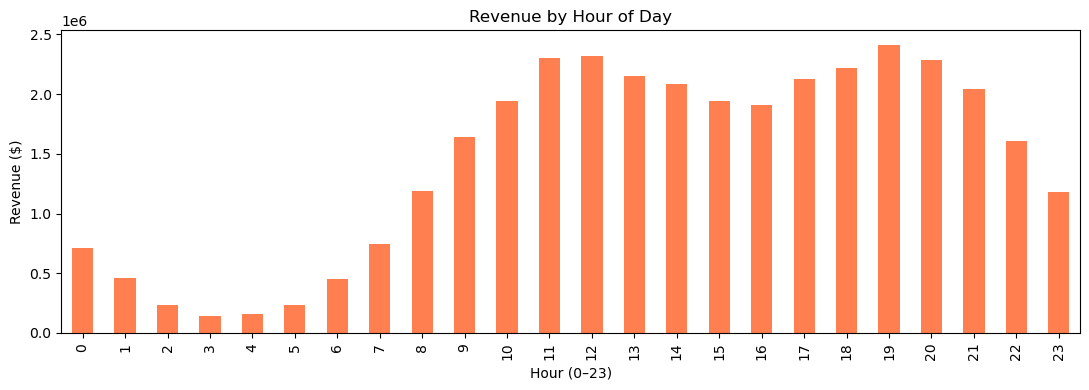

In [41]:
hourly.plot(kind="bar", figsize=(11, 4), color="coral")
plt.title("Revenue by Hour of Day")
plt.xlabel("Hour (0–23)")
plt.ylabel("Revenue ($)")
plt.tight_layout()
plt.show()

In [45]:
# mean vs median (gap)
mean_val = df["Sales"].mean()
median_val = df["Sales"].median()
print(f"Mean line-item value   : ${mean_val:.2f}")
print(f"Median line-item value : ${median_val:.2f}")
print(f"Gap (mean - median)    : ${mean_val - median_val:.2f}")



Mean line-item value   : $185.49
Median line-item value : $14.95
Gap (mean - median)    : $170.54


In [46]:
summary = df.groupby("Product Category").agg(
    Revenue=("Sales", "sum"),
    Quantity=("Quantity Ordered", "sum")
).sort_values("Revenue", ascending=False)

summary.to_csv("category_summary.csv")
summary

,Revenue,Quantity
Product Category,,
Laptops and Computers,12167558.70,8858
Phones and Accessories,8940700.00,14449
Monitors,6377228.78,24122
Audio Devices,3941193.86,49675
Entertainment Devices,1445700.00,4819
Home Appliances,787200.00,1312
Charging Cables,633595.40,47192
Batterie,198859.23,58652
